<table class="table table-bordered">
    <tr>
        <th style="text-align:center; width:25%"><img src='https://www.np.edu.sg/_next/image?url=https%3A%2F%2Fassets.app.optical.gov.sg%2Fnp%2Fproduction%2Fpublished%2Fcollections%2Fpages%2F17c64bb4-8632-49e9-af16-047f7cabe99a%2Fab16008f-a6a0-466e-9193-e16e947261b0.png&w=1080&q=75'"></th>
        <th style="text-align:center;"><h1>SCHOOL OF INFOCOMM TECHNOLOGY <br> Diploma in Data Science</h1><h2>Machine Learning 1: Assignment Coding</h2></th>
    </tr>
</table>


<div style="border:1px solid black; padding:10px; width:300px;"> <strong>
    Student Name: Jaether Chan Xuan (S10273360A)
    <strong><br><br>
</div>



<span style="color:blue; font-size:1.2em;">
<strong>Note: This template provides suggested steps to guide your work. You may include additional steps where appropriate.</strong>
</span><br><br>


## Import the required packages

import libraries to handle data (pandas, numpy, matplotlib, and seaborn)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

import modelling tools that will be used for building models, and regression metrics for evaluation

In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, silhouette_score
from math import sqrt
import statsmodels.api as sm
from sklearn.cluster import KMeans, AgglomerativeClustering
import scipy.cluster.hierarchy as shc

import tools for splitting data to train-test sets, tuning hyperparameters, and scaling features.

In [3]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler

## 1. Task 1: Supervised Learning Using Wine Quality Dataset
Problem Understnading, Objective, and Scope:
- **Business problem**: Wine producers currently rely on tasting panel (humans) to grade wine quality, which is slow, costly, and subjective from person-to-person. This task is to see if lab measurements of physicochemicals can be used to predict a wine's quality score instead. 
- **Objective**: Build a supervised regression model that predicts the quality score of white wine from it's 11 physicochemical features, so quality can be estimated quickly and consistently without a tasting panel.
- **Scope**: Dataset is limited to just **white** wine, which excludes red wine. It contains 4898 records, 11 numerical features + quality score (ranges from 0-10, though only values 3-9 are seen in the dataset). `quality` is used as the target for this regression model.

### 1.1 Load and Explore the Data

load 'winequality-white.csv' and view first 5 rows to get an idea of the types of features and their respective scales

In [4]:
data = pd.read_csv(r"C:\Users\jaeth\Downloads\NP\Y2S1\ML1\ml ASG\Dataset\Data\winequality-white.csv")
data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


Look at dataset's structure. Things like dtypes, non-null counts, num of duplicated rows, and summary statistics for all the features.

In [51]:
data.shape

(4898, 12)

In [52]:
data.info()
print()
print('num of duplicated rows: ', data.duplicated().sum())   
print()
data.describe()

<class 'pandas.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB

num of duplicated rows:  937



,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000
mean,6.854788,0.278241,0.334192,6.391415,0.045772,35.308085,138.360657,0.994027,3.188267,0.489847,10.514267,5.877909
std,0.843868,0.100795,0.121020,5.072058,0.021848,17.007137,42.498065,0.002991,0.151001,0.114126,1.230621,0.885639
min,3.800000,0.080000,0.000000,0.600000,0.009000,2.000000,9.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.300000,0.210000,0.270000,1.700000,0.036000,23.000000,108.000000,0.991723,3.090000,0.410000,9.500000,5.000000
50%,6.800000,0.260000,0.320000,5.200000,0.043000,34.000000,134.000000,0.993740,3.180000,0.470000,10.400000,6.000000
75%,7.300000,0.320000,0.390000,9.900000,0.050000,46.000000,167.000000,0.996100,3.280000,0.550000,11.400000,6.000000
max,14.200000,1.100000,1.660000,65.800000,0.346000,289.000000,440.000000,1.038980,3.820000,1.080000,14.200000,9.000000


All 12 columns are numeric with no missing values, so imputation is not needed. However, there are 937 duplicated rows. They are not immediately removed as there is a possibility that the samples genuinely have the same measurements. The `describe()` output also tell us that the features use very different scales, meaning feature scaling has to be performing later on. 

Plot historgrams of all the features to check their distribution. Looking out for their skewness and possible outliers.

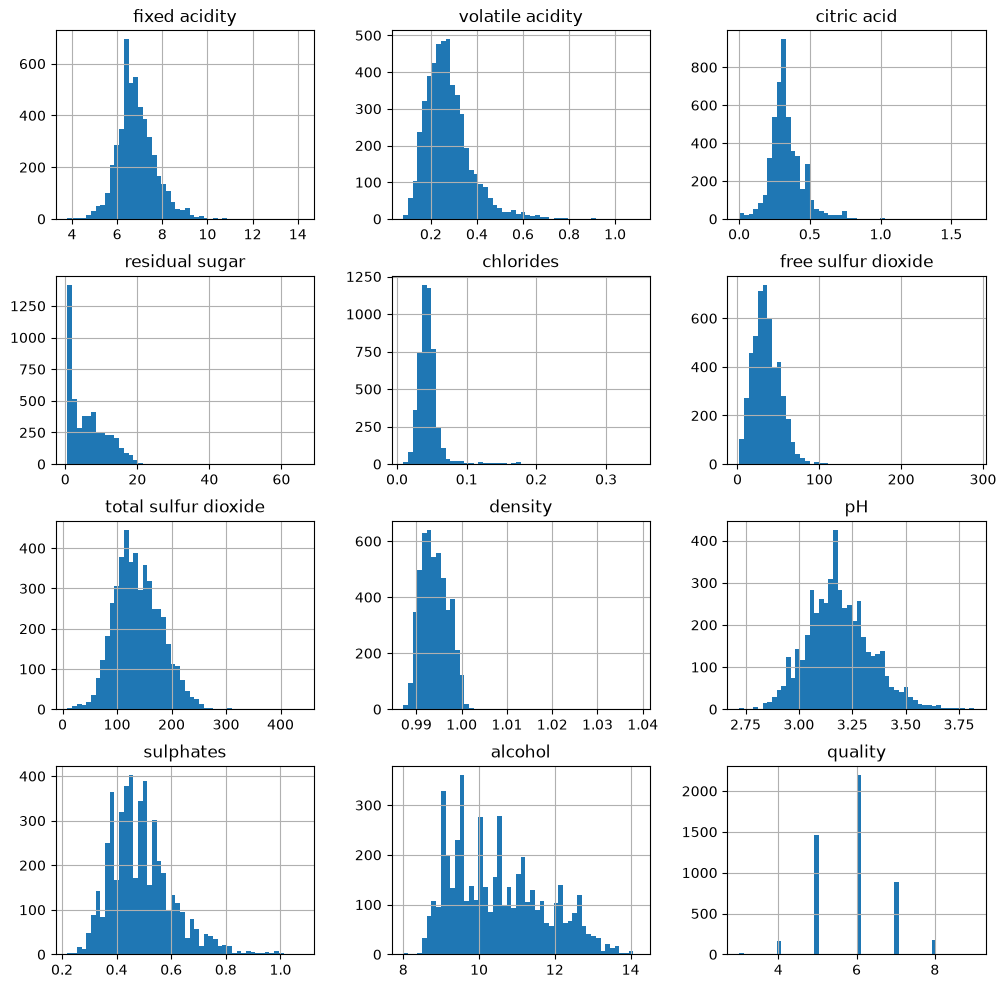

In [53]:
data.hist(bins=50, figsize=(12,12))
plt.show()

Most features like residual sugar, chlorides, free sulfur dioxide, and total sulfur dioxide are right-skewed with long tails. That means that there are outliers. Quality and alcohol looks to have a curve like a normal distribution curve. 

Compute correlation matrix and visualize it (heatmap) to see which features have the highest correlation with 'quality'. also looking to see if there is multicollinearity.

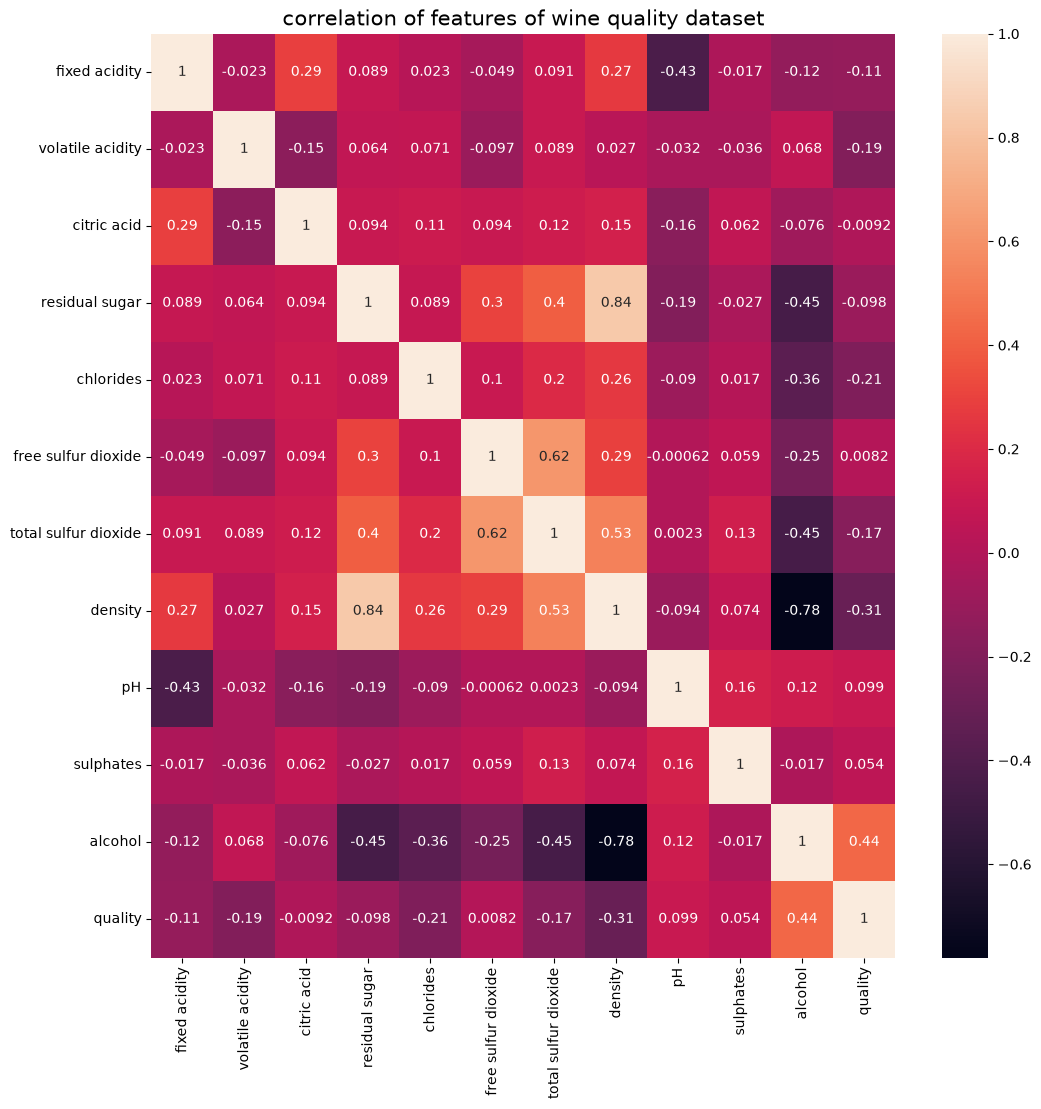

In [54]:
data.corr()

plt.figure(figsize=(12,12))
sns.heatmap(data.corr(), annot=True)
plt.title('correlation of features of wine quality dataset', size=15)
plt.show()

Alcohol has the strongest correlation with the target variable (0.44), followed by weaker positive relations with pH at 0.10 and sulphates at 0.05. There are also negative correlations with the strongest being density (-0.31), followed by chlorides (-0.21) and volatile acidity (-0.19). Density is also quite correlated with residual sugar and alcohol, indicating some multicollinearity among the physicochemical features instead of with quality. 

Generate boxplot for each feature. they all have their own y-axis scale to spot potential outliers per feature.

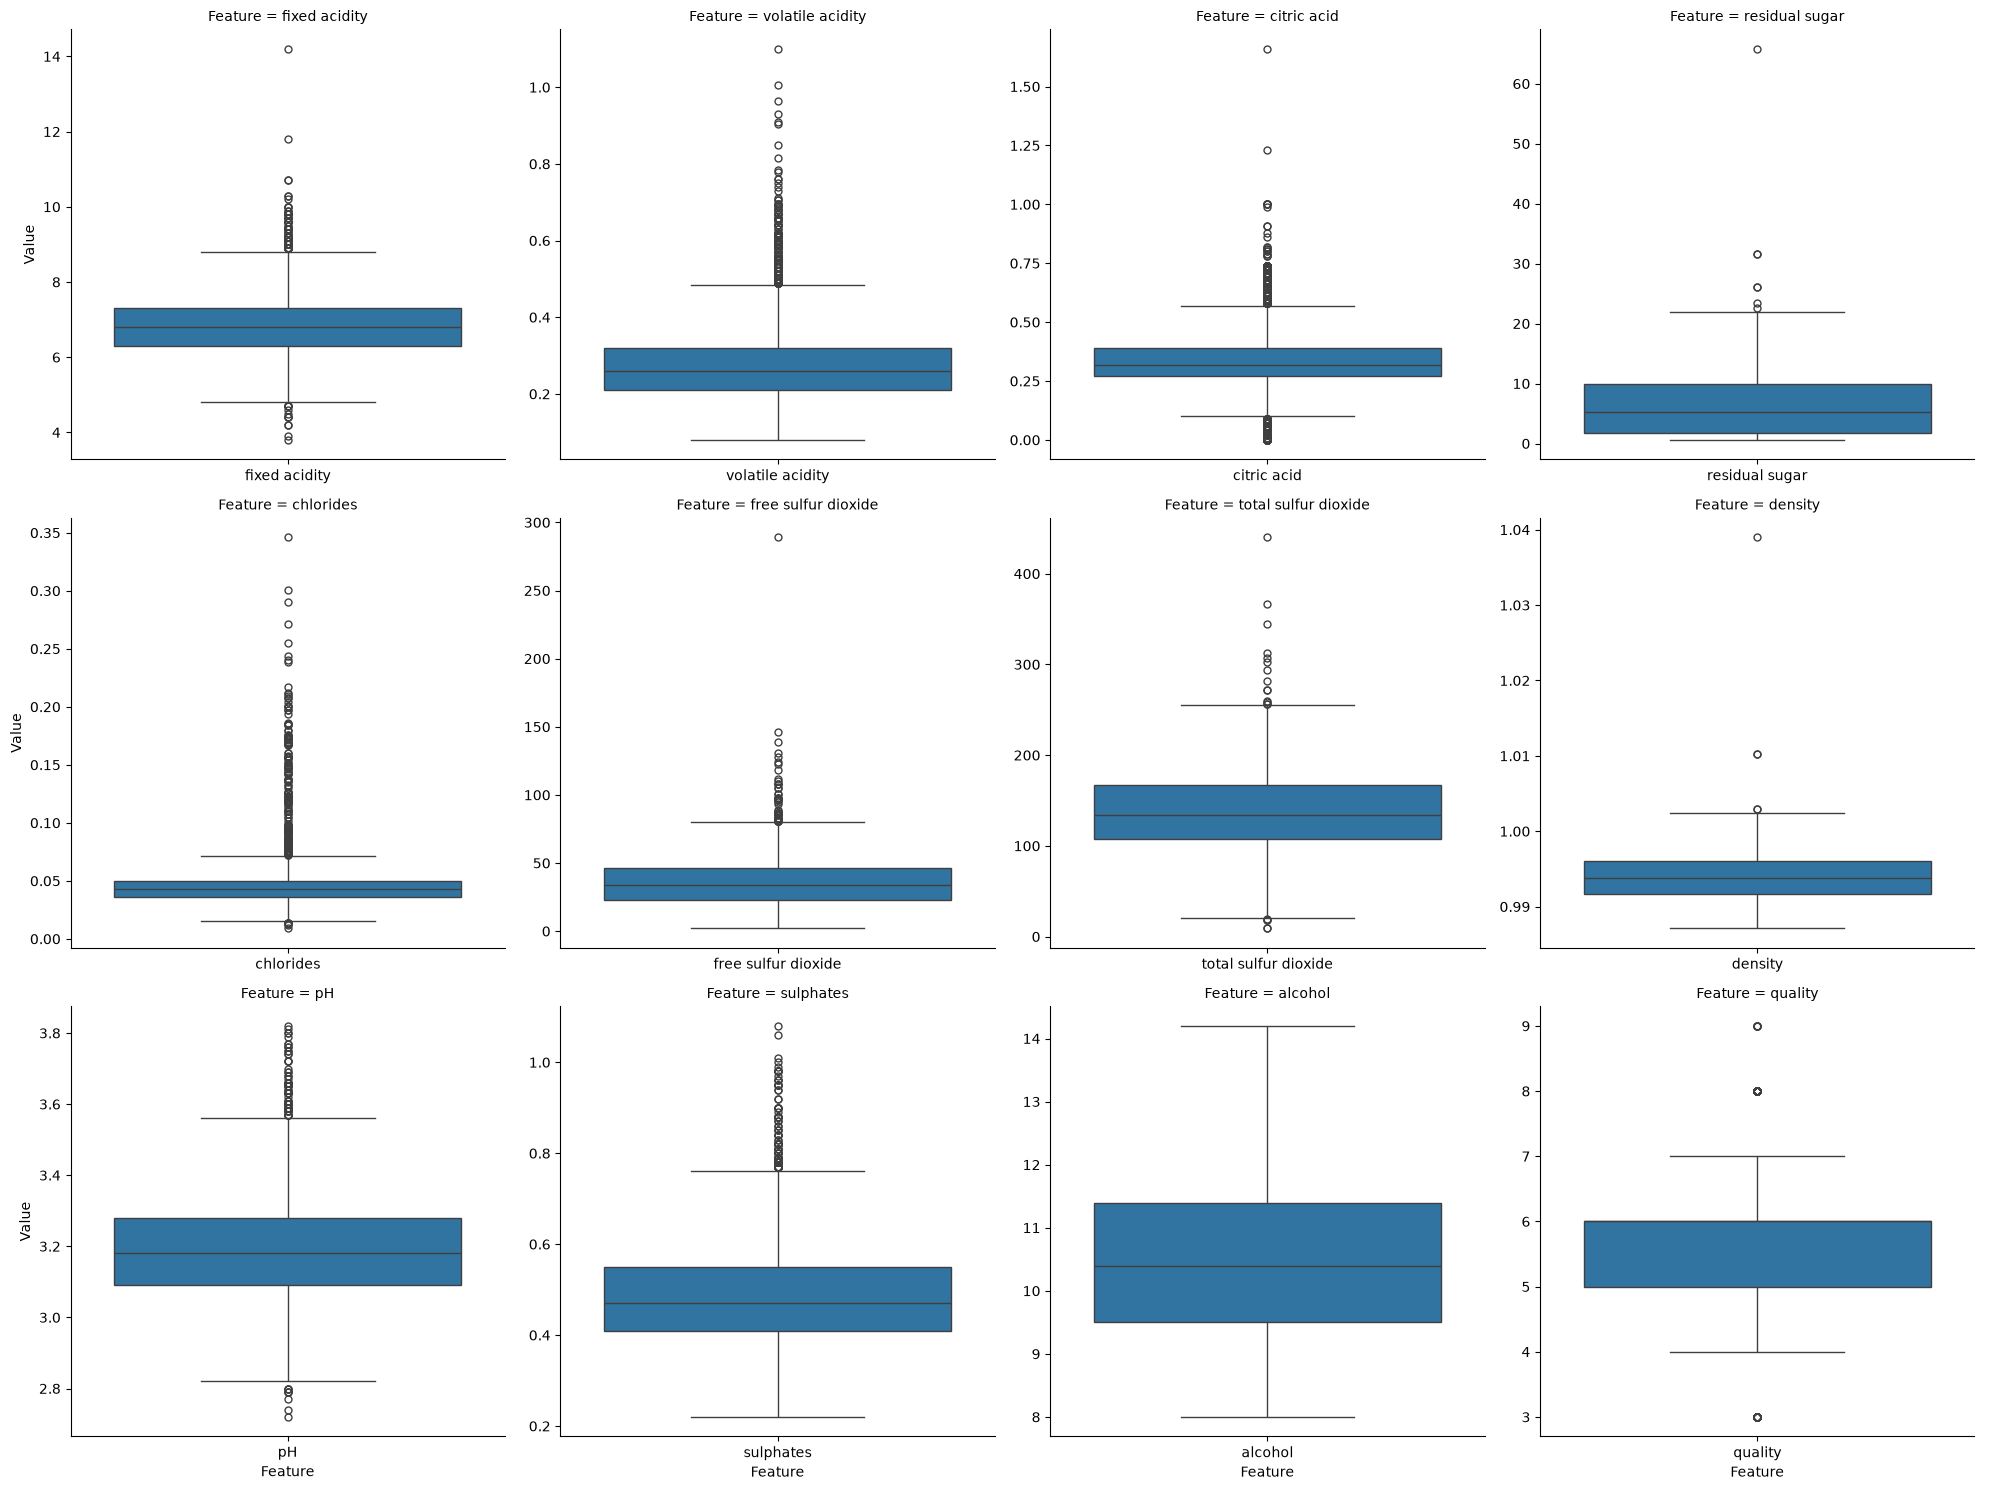

In [55]:
data_long = data.melt(var_name='Feature', value_name='Value')

#plot with unshared y-axes
g = sns.catplot(
    data=data_long, 
    x='Feature', 
    y='Value', 
    col='Feature', 
    kind='box', 
    col_wrap=4,           #num of plots per row
    sharey=False,         #each plot has its own scale
    sharex=False
)

plt.show()

The boxplots confirmed that several features contains quite a bit of outliers. The most visible ones being fixed acidity, volatile acidity, citric acid, chlorides, and sulphates. Alcohol has no outliers. 

See distribution of target variable 'quality' (count per class) and overall mean

In [56]:
print(data['quality'].value_counts().sort_index())
print('Quality mean: ', data['quality'].mean().round(2))

quality
3      20
4     163
5    1457
6    2198
7     880
8     175
9       5
Name: count, dtype: int64
Quality mean:  5.88


The raw quality scores are very imbalanced. Scores 3 and 9 only have 20 and 5 samples respectively. While scores 5 and 6 make up over 74% of the data. This means that the model will have very little data to learn from for the extreme quality scores 3 and 9, so its predictions for those scores should be interpreted with lower confidence compared to the others. 

### 1.2 Data Preparation and Correlation Analysis

Duplicate rows are **retained** rather than dropped since these are physicochemical lab measurements and not IDs, it is entirely plausible for 2 different wine samples to genuinely share identical readings. 

In [57]:
data.shape

(4898, 12)

Split data into train and test sets (70/30) to ensure no data leakage happens when training the model.

In [5]:
#drop target variable 
x = data.drop(['quality'], axis=1)
y = data['quality']

(x_train, x_test, y_train, y_test) = train_test_split(x, y, test_size=0.3, random_state=21)

Using IQR, count how many outliers there are in each feature and only compute them on x_train to avoid data leakage

In [6]:
#compute lower and upper boundary
q1 = x_train.quantile(0.25)  
q3 = x_train.quantile(0.75)
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
lower_bound = q1 - 1.5 * iqr

#outlier count before capping (IQR prox rule):
outliers = ((x_train < lower_bound) | (x_train > upper_bound)).sum().sort_values(ascending=False)
print(f'Before capping ------------')
print(f'Feature            Outliers\n{outliers}')

Before capping ------------
Feature            Outliers
citric acid             194
chlorides               156
volatile acidity        118
sulphates                91
fixed acidity            75
pH                       51
free sulfur dioxide      29
total sulfur dioxide      9
residual sugar            7
density                   5
alcohol                   1
dtype: int64


Citric acid (194), chlorides (156), and volatile acidity (118) have the most IQR outliers, while alchohol only has 1. Outlier counts were not computed on the full dataset, but only `x_train` to avoid data leakage from the test set into the calculation of the outlier boundaries. 

Apply winsorization to replace outliers with their corresponding boundary values.

In [7]:
#replace outliers with upper and lower boundaries
def winsorise(df, variable, upper_limit, lower_limit):
    return np.where(df[variable] > upper_limit, upper_limit, 
                    np.where(df[variable] < lower_limit, lower_limit, df[variable]))

x_train_w = x_train.copy()
x_test_w = x_test.copy()

#apply winsorization to all cols in both train and test
for col in x_train.columns:
    x_train_w[col] = winsorise(x_train, col, upper_bound[col], lower_bound[col])
    x_test_w[col] = winsorise(x_test, col, upper_bound[col], lower_bound[col])

Count outliers after winsorization to make sure they've been capped properly

In [8]:
outliers_after_w = ((x_train_w < lower_bound) | (x_train_w > upper_bound)).sum().sort_values(ascending=False)
print(f'After capping -------------')
print(f'Feature            Outliers\n{outliers_after_w}')

After capping -------------
Feature            Outliers
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
dtype: int64


After winsorization, outlier counts for every feature in `x_train` dropped to 0, confirming that the capping was correctly applied.

Scale features with StandardScaler. Fitting only on x_train

In [9]:
scaler = StandardScaler()
x_train_s = scaler.fit_transform(x_train_w)
x_test_s = scaler.transform(x_test_w)

`StandardScaler` is fit only on `x_train_w` and then used to transform both `x_train_w` and `x_test_w`. This standardised all features which is important for distance-based models like KNN, and keeps the test set fully hidden during fitting. 

## Modelling Strategy and Justification
We will build and compare 2 regression models for predicting `quality`:
1. **Linear Regression**: A baseline that uses quality as a linear combination of the other 11 features. Its coefficients are easy to interpret and it gives quick reads on how much of a variable is explainable linearly. 
2. **Decision Tree Regressor**: It is a contrast from the first model. It is a non-linear model that can capture threshold effects and interactions between features, which is something Linear Regression cannot do. It also does not require feature scaling and its splits can be dissected for interpretability too. 

Comparing a linear model against a non-linear tree-based model will show us whether the relationship between the physicochemical properties and quality is mostly linear or not. Or even whether non-linear relationships matter. This uses the assignment's suggested comparison of Linear Regression vs. Decision Tree Regressor. GirdSearchCV will be used to help tune the decision tree's hyperparameters via cross validation, and both models will be evaludated using MAE, MSE/RMSE, and R².

### 1.3 Build the Machine Learning Models

#### Model 1 - Linear Regression

In [10]:
lm = LinearRegression()
lm.fit(x_train_s, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](11,)","[ 0.09,-0.17, 0.01,..., 0.13, 0.08, 0.12]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,5.876
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,11
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(11)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](11,)","[108.3 , 73.71, 64.88,..., 36.05, 31.3 , 7.22]"


In [64]:
print(f'lm coef: {lm.coef_}')
print(lm.intercept_)

lm coef: [ 0.09055682 -0.17035239  0.01032105  0.50892085 -0.02373399  0.0807428
 -0.00860838 -0.64291174  0.13158852  0.07938984  0.12066124]
5.875729288214702


In [65]:
y_fitted = lm.predict(x_train_s)

train_rmse = sqrt(mean_squared_error(y_train, y_fitted))
train_r2 = lm.score(x_train_s, y_train)

print(f'train rmse: {train_rmse}')  #lower better
print(f'train r2: {train_r2}')   #higher better (0-1)

train rmse: 0.7483768660437483
train r2: 0.28814620560396575


In [66]:
y_pred = lm.predict(x_test_s)

test_rmse = sqrt(mean_squared_error(y_test, y_pred))
test_r2 = lm.score(x_test_s, y_test)

print(f'test rmse: {test_rmse}')
print(f'test r2: {test_r2}')

test rmse: 0.74429011070599
test r2: 0.28809289358723855


#### Model 2 - Decision Tree Regressor

In [11]:
tree_reg = DecisionTreeRegressor(max_depth=3, random_state=2)
tree_reg.fit(x_train_s, y_train)   #trees don't require scaled data, but scaled data is used for consistency. 

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",2
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_

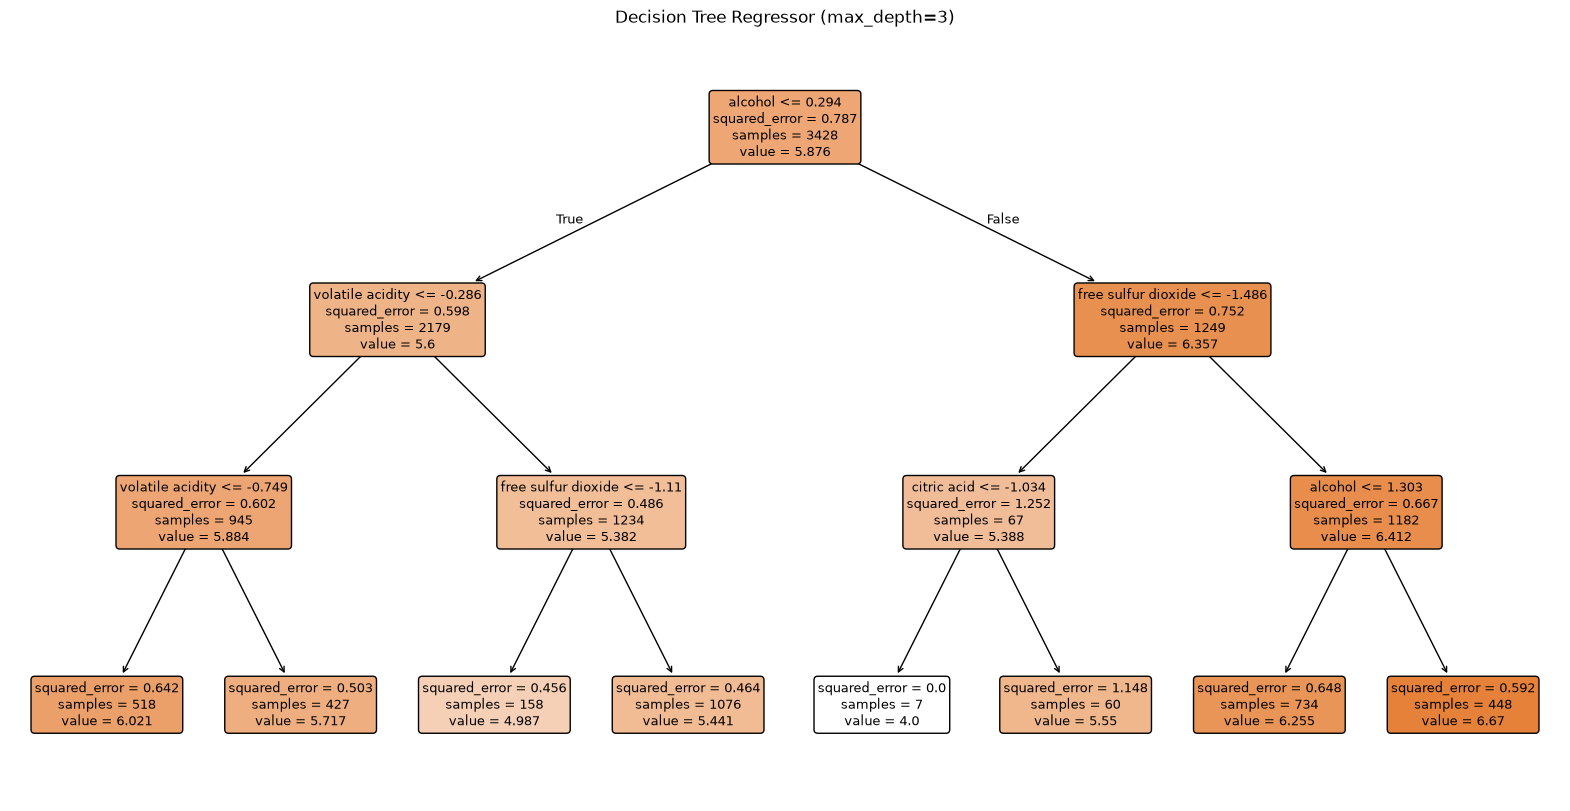

In [68]:
plt.figure(figsize=(20,10))
plot_tree(tree_reg, feature_names=x_train.columns, filled=True, rounded=True, fontsize=9)
plt.title('Decision Tree Regressor (max_depth=3)')
plt.show()

In [69]:
y_fitted_dt = tree_reg.predict(x_train_s)
y_pred_dt = tree_reg.predict(x_test_s)

train_rmse_dt = sqrt(mean_squared_error(y_train, y_fitted_dt))
train_r2_dt = tree_reg.score(x_train_s, y_train)

test_rmse_dt = sqrt(mean_squared_error(y_test, y_pred_dt))
test_r2_dt = tree_reg.score(x_test_s, y_test)

print(f'Train RMSE: {train_rmse_dt}, Train R2: {train_r2_dt}')
print(f'Test RMSE: {test_rmse_dt}, Test R2: {test_r2_dt}')

Train RMSE: 0.7499439494105437, Train R2: 0.2851618744666813
Test RMSE: 0.7596413809248977, Test R2: 0.2584233271027816


<hr>

### 1.4 Evaluate and Improve the Model(s) Performance

#### Improve Model 1 (Linear regression) via feature selection with p-value.
Linear Regression Model has no hyper parametars to be tuned as it has already found out the best line or hyperlane which minimizes RMSE. To further improve the model, we need to utimize `statsmodel` package to find out the p-values for each coefficient so as to understand our confidence levels on each coefficient.(from prac 1a)

In [12]:
x_train_s_df = pd.DataFrame(x_train_s, columns=x_train.columns)
x_train_sm = sm.add_constant(x_train_s_df)

ols_model = sm.OLS(y_train.values, x_train_sm).fit()
ols_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.288
Model:                            OLS   Adj. R-squared:                  0.286
Method:                 Least Squares   F-statistic:                     125.7
Date:                Sat, 01 Aug 2026   Prob (F-statistic):          1.93e-242
Time:                        13:52:58   Log-Likelihood:                -3870.5
No. Observations:                3428   AIC:                             7765.
Df Residuals:                    3416   BIC:                             7839.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    5.8757      0.013    458.881      0.000       5.851       5.901
fixed acidity            0.0906      0.023      3.962      0.000       0.046       0.135
volatile acidity        -0.1704      0.014    -12.478      0.000      -0.197      -0.144
citric acid              0.0103      0.014      0.748      0.454      -0.017       0.037
residual sugar           0.5089      0.051     10.032      0.000       0.409       0.608
chlorides               -0.0237      0.016     -1.513      0.130      -0.054       0.007
free sulfur dioxide      0.0807      0.017      4.668      0.000       0.047       0.115
total sulfur dioxide    -0.0086      0.020     -0.439      0.661      -0.047       0.030
density                 -0.6429      0.080     -8.051      0.000      -0.799      -0.486
pH                       0.1316      0.020      6.582      0.000       0.092       0.171
sulphates                0.0794      0.014      5.717      0.000       0.052       0.107
alcohol                  0.1207      0.042      2.882      0.004       0.039       0.203
==============================================================================
Omnibus:                       65.344   Durbin-Watson:                   1.990
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              131.816
Skew:                           0.055   Prob(JB):                     2.38e-29
Kurtosis:                       3.954   Cond. No.                         15.0
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

From looking at p values, <b>remove</b>:
- citric acid (0.454)
- chlorides (0.130)
- total sulfur dioxide (0.661)

In [13]:
kept_feat_pval = ['fixed acidity', 'volatile acidity', 
                  'residual sugar', 'free sulfur dioxide', 
                  'density', 'pH', 'sulphates', 'alcohol']

x_train_pval = x_train_w[kept_feat_pval]
x_test_pval = x_test_w[kept_feat_pval]

x_train_pval_s = scaler.fit_transform(x_train_pval)
x_test_pval_s = scaler.transform(x_test_pval)

lm_pval = LinearRegression()
lm_pval.fit(x_train_pval_s, y_train)

y_fitted_pval = lm_pval.predict(x_train_pval_s)
y_pred_pval = lm_pval.predict(x_test_pval_s)

train_rmse_pval = sqrt(mean_squared_error(y_train, y_fitted_pval))
train_r2_pval = lm_pval.score(x_train_pval_s, y_train)
test_rmse_pval = sqrt(mean_squared_error(y_test, y_pred_pval))
test_r2_pval = lm_pval.score(x_test_pval_s, y_test)

print(f'Train RMSE: {train_rmse_pval}, Train R2: {train_r2_pval}')
print(f'Test RMSE: {test_rmse_pval}, Test R2: {test_r2_pval}')

Train RMSE: 0.7487115141967273, Train R2: 0.28750943065733536
Test RMSE: 0.7444097883576334, Test R2: 0.2878639338865864


Proves that the 3 features that were dropped are not that significant. (Justifies remove those features)
<hr>

#### Use GridSearchCV to improve Model 2 (Decison Tree)

In [72]:
param_grid = {'max_depth' : [2, 3, 4, 5, 6, 7, 8, 9, 10],
              'min_samples_split' : [2, 5, 10, 15, 20],
              'min_samples_leaf' : [1, 5, 10, 15, 20, 25, 30, 35]}

gs_dt = GridSearchCV(tree_reg, param_grid=param_grid, scoring='neg_mean_squared_error', cv=5, n_jobs=-1)

gs_dt.fit(x_train_s, y_train)

print(f'best param: {gs_dt.best_params_}')
print(f'best score: {sqrt(-gs_dt.best_score_)}')

best param: {'max_depth': 8, 'min_samples_leaf': 25, 'min_samples_split': 2}
best score: 0.7419851019443047


##### Rebuild the Decision Tree

In [14]:
tree_reg_gs = DecisionTreeRegressor(max_depth=8, min_samples_leaf=25, min_samples_split=2, random_state=2)
tree_reg_gs.fit(x_train_s, y_train)

y_fitted_dt_gs = tree_reg_gs.predict(x_train_s)
y_pred_dt_gs = tree_reg_gs.predict(x_test_s)

train_rmse_dt_gs = sqrt(mean_squared_error(y_train, y_fitted_dt_gs))
train_r2_dt_gs = tree_reg_gs.score(x_train_s, y_train)

test_rmse_dt_gs = sqrt(mean_squared_error(y_test, y_pred_dt_gs))
test_r2_dt_gs = tree_reg_gs.score(x_test_s, y_test)

print(f'train rmse: {train_rmse_dt_gs}, train r2: {train_r2_dt_gs}')
print(f'test rmse: {test_rmse_dt_gs}, test r2: {test_r2_dt_gs}')

train rmse: 0.6605792604883827, train r2: 0.44537433152370676
test rmse: 0.7361576165775721, test r2: 0.30356522171068423


In [15]:
importances = pd.Series(tree_reg_gs.feature_importances_, index=x_train.columns)
importances.sort_values(ascending=False)

alcohol                 0.459964
volatile acidity        0.152297
free sulfur dioxide     0.117846
pH                      0.047109
residual sugar          0.042494
total sulfur dioxide    0.040501
chlorides               0.034935
sulphates               0.034021
density                 0.026622
fixed acidity           0.022850
citric acid             0.021361
dtype: float64

In [76]:
comparison = pd.DataFrame({
    'Model': ['Linear Regression (Full)', 'Linear Regression (Feat Selected)', 
              'Decision Tree (Untuned)', 'Decision Tree (Tuned)'],
    'Train RMSE': [train_rmse, train_rmse_pval, train_rmse_dt, train_rmse_dt_gs],
    'Test RMSE': [test_rmse, test_rmse_pval, test_rmse_dt, test_rmse_dt_gs],
    'Train R2': [train_r2, train_r2_pval, train_r2_dt, train_r2_dt_gs],
    'Test R2': [test_r2, test_r2_pval, test_r2_dt, test_r2_dt_gs],
})

# Add a column showing the train-test R² gap (a quick overfitting indicator)
comparison['R2 Gap (Train - Test)'] = comparison['Train R2'] - comparison['Test R2']

comparison.round(4)

,Model,Train RMSE,Test RMSE,Train R2,Test R2,R2 Gap (Train - Test)
0,Linear Regression (Full),0.7484,0.7443,0.2881,0.2881,0.0001
1,Linear Regression (Feat Selected),0.7487,0.7444,0.2875,0.2879,-0.0004
2,Decision Tree (Untuned),0.7499,0.7596,0.2852,0.2584,0.0267
3,Decision Tree (Tuned),0.6606,0.7362,0.4454,0.3036,0.1418


<hr>

### 1.5 Summarize the Findings
- Recommend the best model for predicting wine quality and explain why it performs better than
the other model(s).
#### Test RMSE and R2 across all 4 models

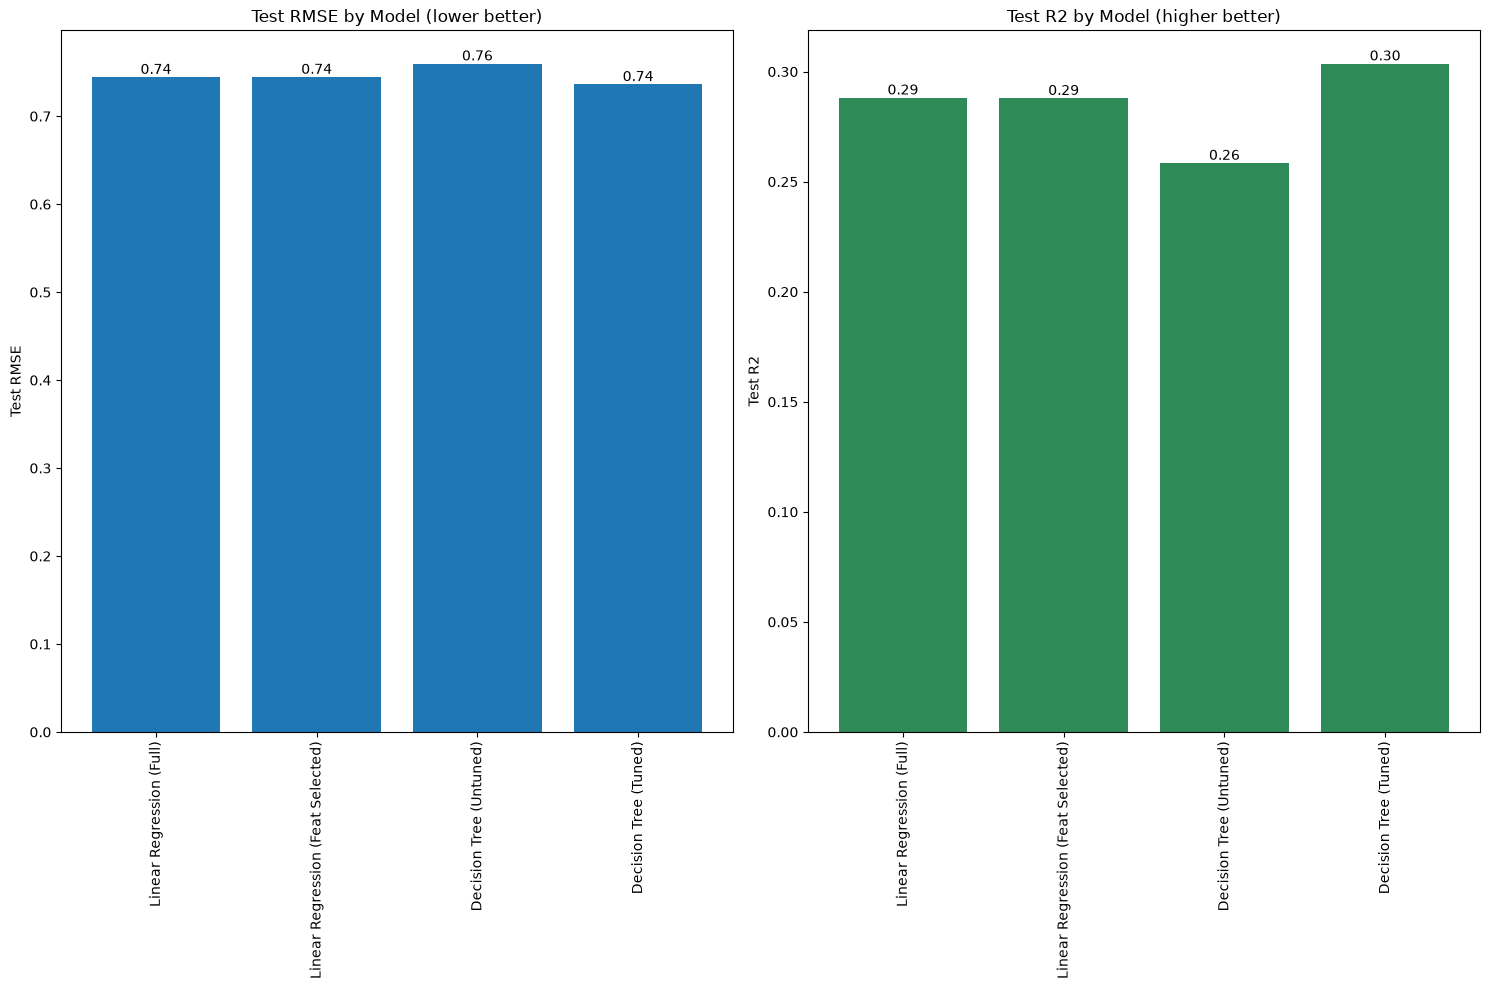

In [77]:
fig, axes = plt.subplots(1, 2, figsize=(15,10))

bar0 = axes[0].bar(comparison['Model'], comparison['Test RMSE'])
axes[0].set_title('Test RMSE by Model (lower better)')
axes[0].set_ylabel('Test RMSE')
axes[0].tick_params(axis='x', rotation=90)
axes[0].bar_label(bar0, fmt='%.2f')

bar1 = axes[1].bar(comparison['Model'], comparison['Test R2'], color='seagreen')
axes[1].set_title('Test R2 by Model (higher better)')
axes[1].set_ylabel('Test R2')
axes[1].tick_params(axis='x', rotation=90)
axes[1].bar_label(bar1, fmt='%.2f')

plt.tight_layout()
plt.show()

## Actual vs Predicted scatterplot

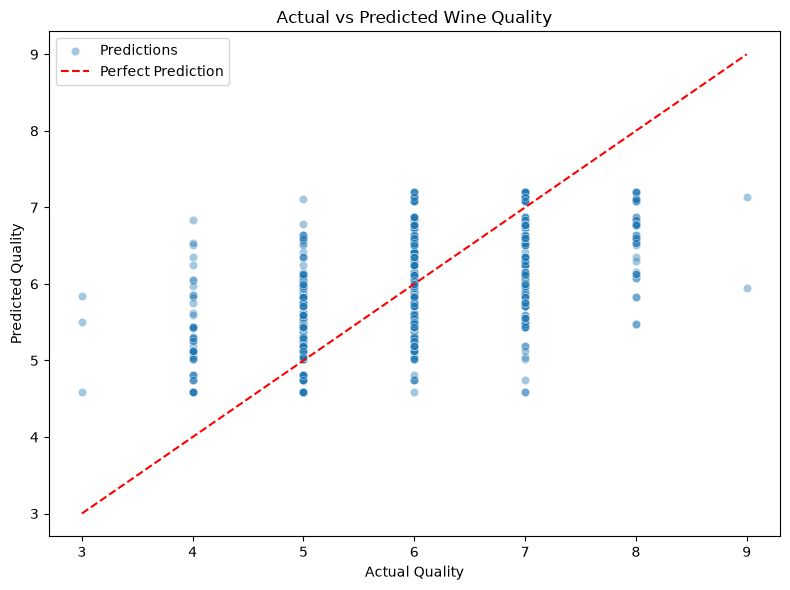

In [78]:
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred_dt_gs, alpha=0.4, edgecolors='white', linewidth=0.5, label='Predictions')

min_val = min(y_test.min(), y_pred_dt_gs.min())
max_val = max(y_test.max(), y_pred_dt_gs.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=1.5, label='Perfect Prediction')

plt.xlabel('Actual Quality')
plt.ylabel('Predicted Quality')
plt.title('Actual vs Predicted Wine Quality')
plt.legend()
plt.tight_layout()
plt.show()

## Importance bar chart

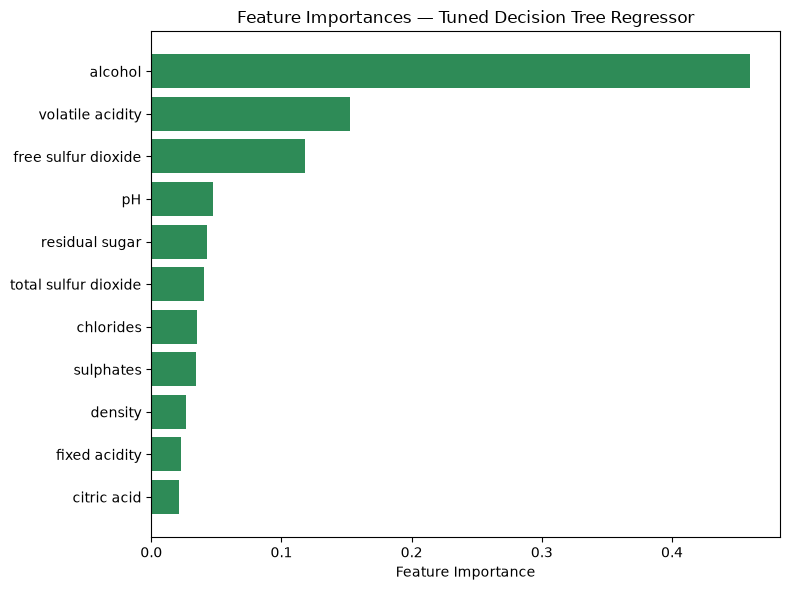

In [28]:
importances_sorted = importances.sort_values(ascending=True)  #biggest bar ends up on top

plt.figure(figsize=(8,6))
plt.barh(importances_sorted.index, importances_sorted.values, color='seagreen')
plt.xlabel('Feature Importance')
plt.title('Feature Importances — Tuned Decision Tree Regressor')
plt.tight_layout()
plt.show()

#### Summary
For task 1, 4 regression model varients were compared. Linear Regression and its feature-selected variant performed identically, showing that dropping the 3 insignificant features, did not cost the model any predictive power. <br><br>
The untuned Decision Tree underperformed both linear models, but GridSearchVC tuning gave it the best test RMSE of 0.736 and test R2 of 0.304 of the four, though it was at the cost of a wide train-test gap, which suggest mild overfitting. Alcohol, volatile, and free sulfure dioxide stood out as the most influential features across both correlation analysis and the tuned tree's feature importances.

#### Recommendation: Decision Tree (Tuned)
Reason: The tuned Decision Tree Regressor model performed the best. It achieved the lowest test error and highest test R2 among the four models. This model pointed towards alcohol, volatile acidity, and free sulfur dioxide as the main variables driving the wine's score. This matches without earlier data checks that already showed that higher-scoring wines tend to have higher alcohol contents. 

However, the wider train-test gap means its performance advantage over linear regression may be limited in practice. For further improvement, collecting more data, especially for scores that have very little samples (3 and 9) would help close the train-test gap.

<hr>

## 2. Task 2: Unsupervised Learning Using Online Retail Dataset

## Problem understanding, objective, and scope
- **Business problem**: A retailer currently treats all customers the same during marketing campaigns. Meaning high value customers and one-time shoppers are getting the same treatment which is not efficient use of resources. 
- **Objective**: Use unsupervised learning to segment customer into groups based on their purchasing behaviours, to help the business target each segment with more targetted marketing strategies. 
- **Scope**: Customers are described using engineered RFM features: Recency, Frequency, and Monetary value (including Average order value) rather than raw transaction data. 

### 2.1 Load and Explore the Data

In [16]:
df = pd.read_csv(r"C:\Users\jaeth\Downloads\NP\Y2S1\ML1\ml ASG\Dataset\Data\online_retail.csv")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01/12/2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01/12/2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01/12/2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01/12/2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01/12/2010 08:26,3.39,17850.0,United Kingdom


In [80]:
print(f'Shape of dataset: {df.shape}\n')
df.info()

Shape of dataset: (541909, 8)

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


Check for missing values

In [81]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Missing Customer details

In [82]:
print(df['CustomerID'].isnull().value_counts())
print(f'% of missing CustomerID: {df['CustomerID'].isnull().mean() * 100:.2f}')
print()
print(df['Description'].isnull().value_counts())
print(f'% of missing Description: {df['Description'].isnull().mean() * 100:.2f}')

CustomerID
False    406829
True     135080
Name: count, dtype: int64
% of missing CustomerID: 24.93

Description
False    540455
True       1454
Name: count, dtype: int64
% of missing Description: 0.27


About 24.9% of rows have a missing CustomerID. Since segmentation tasks is inherently customer-level, these rows cannot be assigned to any customers. Since they cannot be imputed meaningfully, they must be dropped later on in section 2.2. 
Description has only 0.27% missing, which is not used for clustering so it is left alone. 

Summary of numerical features

In [83]:
df[['Quantity', 'UnitPrice']].describe()

,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


Check unique counts in key fields

In [17]:
#convert InvoiceDate to datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], format='%d/%m/%Y %H:%M')

In [85]:
print('Unique Invoices: ', df['InvoiceNo'].nunique())
print('Unique Customers: ', df['CustomerID'].nunique())
print('Unique Countries: ', df['Country'].nunique())
print(f'Date range: {df['InvoiceDate'].min()} to {df['InvoiceDate'].max()}')

Unique Invoices:  25900
Unique Customers:  4372
Unique Countries:  38
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


The data set contains 259000 unique invoices, 4372 unique customers, across 38 countries over roughly a one year period from December 2010 to December 2011. This confirms that there is enough cutsomers to segment and that InvoiceDate can be used to calculate Recency for RFM (once a reference data is set).

Distribution of Quantity and UnitPrice

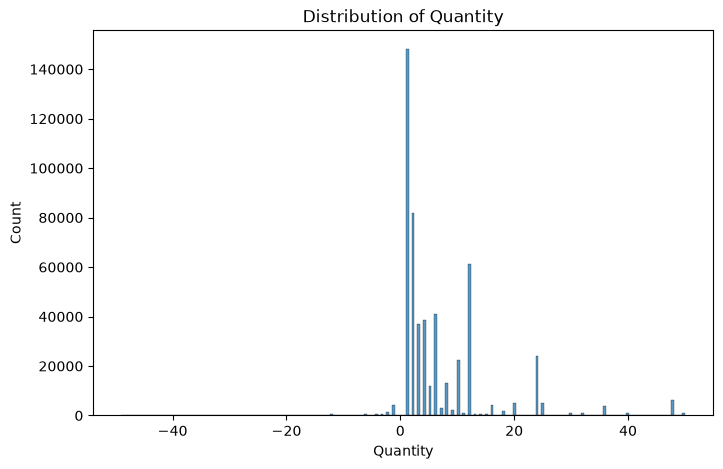

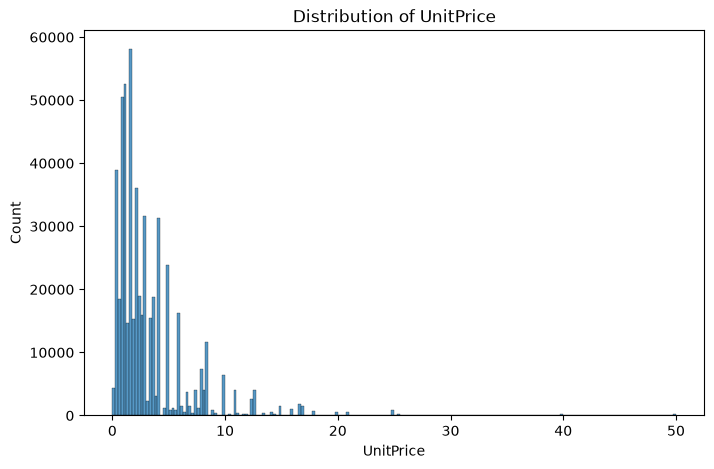

In [86]:
ax1 = plt.figure(figsize=(8,5))
subset_qty = df[(df['Quantity'] > -50) & (df['Quantity'] <= 50)]
ax1 = sns.histplot(subset_qty['Quantity'], bins=200)
ax1 = plt.title('Distribution of Quantity')

ax2 = plt.figure(figsize=(8,5))
subset_price = df[(df['UnitPrice'] > 0) & (df['UnitPrice'] <= 50)]
ax2 = sns.histplot(subset_price['UnitPrice'], bins=200)
ax2 = plt.title('Distribution of UnitPrice')

plt.show()

Both Quantity and UnitPrice are skewed to the right with a small number of outliers. This supports the push of the outlier treatment that will be done in the data cleansing step later. 

Outliers in UnitPrice, Quantity, and invoice totals.

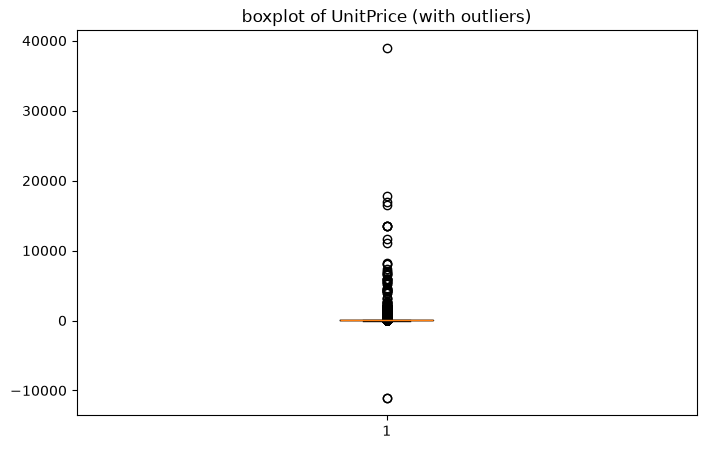

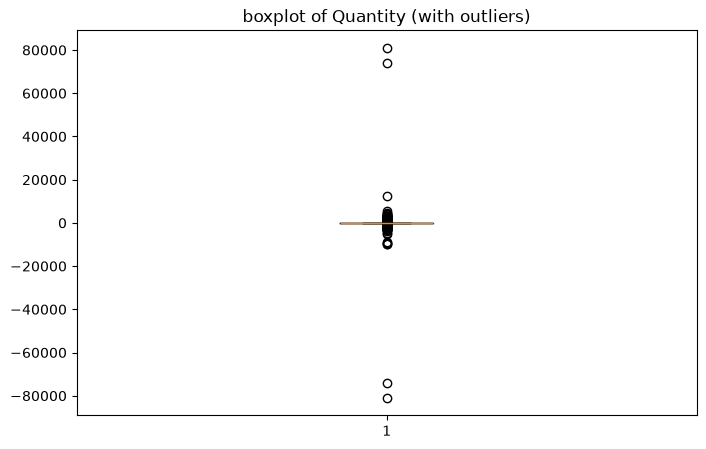

In [87]:
plt.figure(figsize=(8,5))
plt.boxplot(x=df['UnitPrice'])
plt.title('boxplot of UnitPrice (with outliers)')

plt.figure(figsize=(8,5))
plt.boxplot(x=df['Quantity'])
plt.title('boxplot of Quantity (with outliers)')

plt.show()

These boxplots confirm significant outliers in both UnitPrice and Quantity, even including negative Quantity values that correspond to returns or cancellations, which have to be removed later on instead of being kept the same and treated as statistical outliers. 

Check to see how many cancelled invoices to remove later on.

In [7]:
# boolean mask: True where InvoiceNo starts with 'C'
cancelled = df['InvoiceNo'].astype(str).str.startswith('C')

# use the mask to filter the dataframe -> returns the actual rows
cancelled_rows = df[cancelled]

print(f'num of rows to be removed: {cancelled_rows.shape[0]}')  
cancelled_rows[['InvoiceNo', 'CustomerID', 'Quantity', 'UnitPrice', 'InvoiceDate']].head(15)    

num of rows to be removed: 9288


,InvoiceNo,CustomerID,Quantity,UnitPrice,InvoiceDate
141,C536379,14527.0,-1,27.50,2010-12-01 09:41:00
154,C536383,15311.0,-1,4.65,2010-12-01 09:49:00
235,C536391,17548.0,-12,1.65,2010-12-01 10:24:00
236,C536391,17548.0,-24,0.29,2010-12-01 10:24:00
237,C536391,17548.0,-24,0.29,2010-12-01 10:24:00
238,C536391,17548.0,-24,0.29,2010-12-01 10:24:00
239,C536391,17548.0,-12,3.45,2010-12-01 10:24:00
240,C536391,17548.0,-12,1.65,2010-12-01 10:24:00
241,C536391,17548.0,-24,1.65,2010-12-01 10:24:00
939,C536506,17897.0,-6,4.25,2010-12-01 12:38:00


9288 rows from InvoiceNo start with 'C', indicating that they are cancelled invoices, which have negative Quantity values representing returns too. These do not count as genuine purchases so they have to be removed to keep the customer's purchase behaviour as accurate as possible. 

Check to see how many rows have non-positive Quantity or UnitPrice.

In [89]:
print('Rows with non positives:')
print('Quantity: ', (df['Quantity'] <= 0).sum())
print('UnitPrice: ', (df['UnitPrice'] <= 0).sum())

Rows with non positives:
Quantity:  10624
UnitPrice:  2517


Other than cancelled invoices, there are still 10624 rows with non-positive Quantity and 2517 rows with non-positive UnitPrice. These are to be removed since they do not represent valid transactions and would distory the RFM features, specifically monetary (average value).

The top countries sorted by the number of transactions made

In [90]:
df['Country'].value_counts().head(10)

Country
United Kingdom    495478
Germany             9495
France              8557
EIRE                8196
Spain               2533
Netherlands         2371
Belgium             2069
Switzerland         2002
Portugal            1519
Australia           1259
Name: count, dtype: int64

The transactions in this dataset are dominated by the United Kingdom, with Germany, France, and EIRE following at a far distance. Observing this imbalance, Country will not be directly used as a clustering feature. RFM behaviour will be treated the same across customers regardless of the country for this analysis.

### 2.2 Cleanse and Transform the Data

Remove cancelled invoices

In [18]:
df_clean = df.dropna(subset=['CustomerID']).copy()
df_clean.shape

(406829, 8)

Remove all cancelled invoices and check that there isn't any more of them.

In [19]:
df_clean = df_clean[~df_clean['InvoiceNo'].astype(str).str.startswith('C')]
df_clean['InvoiceNo'].astype(str).str.startswith('C').sum()

np.int64(0)

Only keep **valid** records in UnitPrice and Quantity.

In [20]:
df_clean = df_clean[(df_clean['UnitPrice'] > 0) & (df_clean['Quantity'] > 0)]
print(f'num of records now: {df_clean.shape[0]}')

num of records now: 397884


Calculate Invoice totals (`TotPrice`)

In [21]:
df_clean['TotPrice'] = df_clean['Quantity'] * df_clean['UnitPrice']

Find outliers.

In [22]:
def cap_outliers_IQR (data, col):
    q1 = data[col].quantile(0.25)
    q3 = data[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    data[col] = data[col].clip(lower=lower, upper=upper)
    return data

for col in ['UnitPrice','Quantity','TotPrice']:
    df_clean = cap_outliers_IQR(df_clean, col)

In [96]:
df_clean[['UnitPrice','Quantity','TotPrice']].describe()

,UnitPrice,Quantity,TotPrice
count,397884.000000,397884.000000,397884.000000
mean,2.598157,8.317218,14.384227
std,2.103076,8.097234,11.984448
min,0.001000,1.000000,0.001000
25%,1.250000,2.000000,4.680000
50%,1.950000,6.000000,11.800000
75%,3.750000,12.000000,19.800000
max,7.500000,27.000000,42.480000


After removing cancelled/invalid rows and capping outliers with the IQR rules, UnitPrice , Quantity, and TotPrice all have must tighter and more realistic ranges. This will provide a cleaner base for aggregating to the customer-level RFM features.

Feature Engineering - aggregate to customer level

In [23]:
ref_date = df_clean['InvoiceDate'].max()

rfm = df_clean.groupby('CustomerID').agg(     #bundles every cust's transactions together
    Recency=('InvoiceDate', lambda x: (ref_date - x.max()).days),   #lambda js lets you skip naming a function and defining it separately.
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('TotPrice', 'sum')
).reset_index()    #index back to columns for clean dataframe

Average value per person

In [24]:
rfm['AvgVal'] = rfm['Monetary'] / rfm['Frequency']

print(f'num of customers after cleaning: {rfm.shape[0]}')
rfm.head()

num of customers after cleaning: 4338


,CustomerID,Recency,Frequency,Monetary,AvgVal
0,12346.0,325,1,42.48,42.480000
1,12347.0,1,7,3769.34,538.477143
2,12348.0,74,4,1111.40,277.850000
3,12349.0,18,1,1442.71,1442.710000
4,12350.0,309,1,334.40,334.400000


Scale features

In [25]:
rfm_scaler = StandardScaler()

feat = ['Recency', 'Frequency', 'Monetary', 'AvgVal']
rfm_s = rfm_scaler.fit_transform(rfm[feat])

#convert to pandas dataframe
rfm_s_df = pd.DataFrame(rfm_s, columns=feat)
rfm_s_df.head()

,Recency,Frequency,Monetary,AvgVal
0,2.334574,-0.425097,-0.399590,-1.048928
1,-0.905340,0.354417,0.766730,0.979675
2,-0.175360,-0.035340,-0.065072,-0.086277
3,-0.735345,-0.425097,0.038612,4.677941
4,2.174578,-0.425097,-0.308234,0.145010


## Modelling Strategy and Justification
I will build and compare two clustering models on the scaled RFM features:
1. K-Means Clustering: The standard choice customer segmenetaion since it scales well to thousands of customers and outputs easily interpretable centroids. The optimal k will be chosen through the elbow method (SSE) and cross-checked with silhouette score,
2. Agglomerative (Hierarchical) Clustering: Which does not require me to specify the numbers of cluster upfront. A dendrogram will be used to look at the natural groupings before deciding if I will reduce the number of groups. The results will again be validated with the silhouette score across a range of k.

### 2.3 Build the Clustering Models

#### Find optimal number of clusters for KMeans 
Use elbow method where k ranges from 1 to 10.

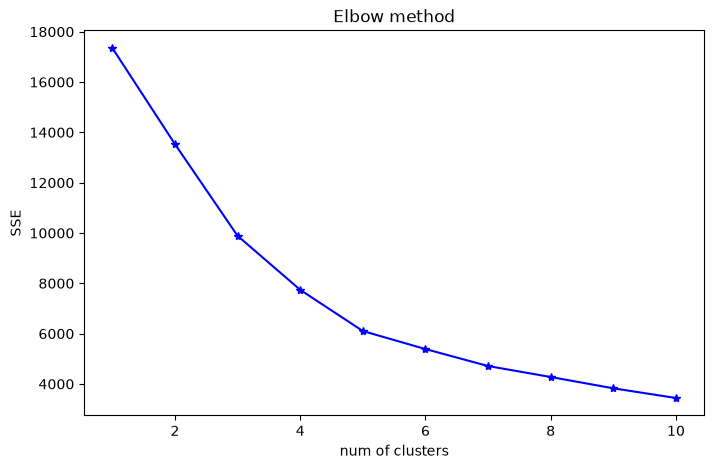

In [16]:
sse = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, n_init=20, random_state=1)
    kmeans.fit(rfm_s_df)
    sse.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(range(1,11), sse, 'b-*')
plt.title('Elbow method')
plt.xlabel('num of clusters')
plt.ylabel('SSE')
plt.show()

The plot shows the SSE dropping sharply around k = 4-5 before plateauing. The optimal k lies in that range. Cross check with silhouette score for the different Ks.

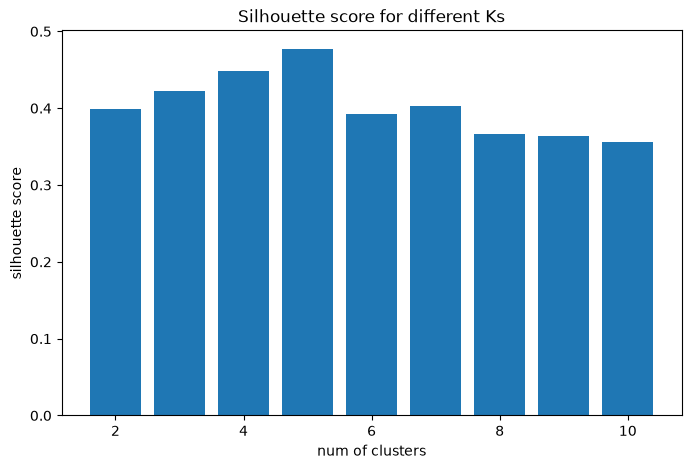

In [17]:
silhouette = []  #score is only defined for k >= 2, unlike SSE where it can be >= 1.
for k in range(2,11):
    kmeans = KMeans(n_clusters=k, n_init=20, random_state=1)
    labels = kmeans.fit_predict(rfm_s_df)
    silhouette.append(silhouette_score(rfm_s_df, labels))

plt.figure(figsize=(8,5))
plt.bar(range(2,11), silhouette)
plt.title('Silhouette score for different Ks')
plt.xlabel('num of clusters')
plt.ylabel('silhouette score')
plt.show()

In [18]:
for k, s in zip(range(2,11), silhouette):
    print(f'k={k}: silhouette - {s:.4f}')  #zip: pairs each number (representing k) with its corresponding silhouette score

k=2: silhouette - 0.3984
k=3: silhouette - 0.4220
k=4: silhouette - 0.4480
k=5: silhouette - 0.4773
k=6: silhouette - 0.3928
k=7: silhouette - 0.4034
k=8: silhouette - 0.3668
k=9: silhouette - 0.3633
k=10: silhouette - 0.3558


k = 5 produces the highest silhouette score while also sitting at the bend of the elbow plot. Therefore, k=5 will be chosen as the optimal k value. 

#### Build KMeans model

In [26]:
k = 5

km = KMeans(n_clusters=k, n_init=20, random_state=1)
rfm['km_cluster'] = km.fit_predict(rfm_s_df)

print(f'k means cluster sizes:\n{rfm['km_cluster'].value_counts().sort_index()}')
print(f'silhouette score (k=5): {silhouette_score(rfm_s_df, rfm['km_cluster'])}')

k means cluster sizes:
km_cluster
0    2737
1    1016
2     335
3       9
4     241
Name: count, dtype: int64
silhouette score (k=5): 0.47726905246431717


<hr>

#### Build Hierarchical(Agglomerative) clustering model
First, generate dendrogram with linkage=Ward

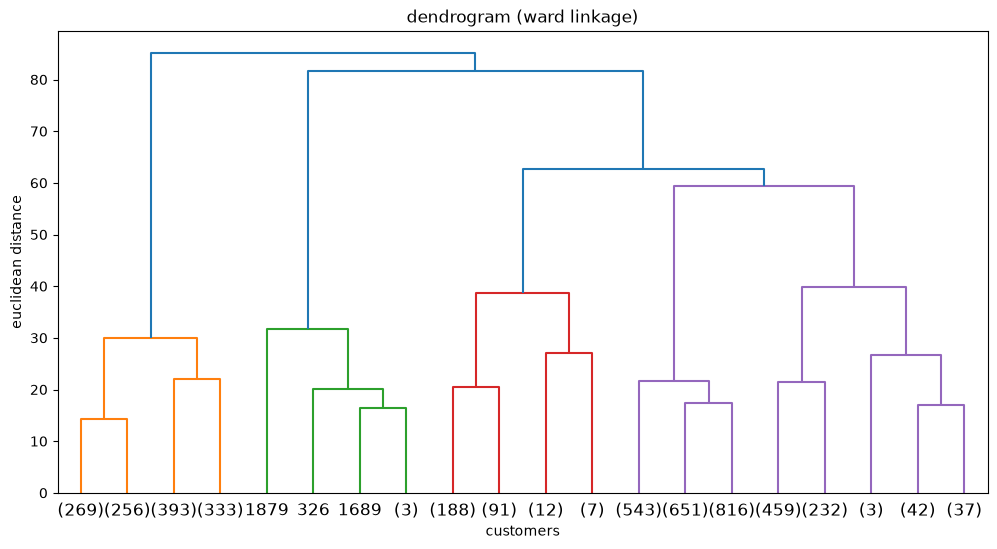

In [104]:
z = shc.linkage(rfm_s_df, method='ward')

plt.figure(figsize=(12,6))
plt.title('dendrogram (ward linkage)')
plt.xlabel('customers')
plt.ylabel('euclidean distance')
shc.dendrogram(z, truncate_mode='lastp', p=20, show_leaf_counts=True)
plt.show()

By calcualting the mid point of the longest vertical section that does not intersect any horizontal lines. with the max around 85 and starts around 30. the length of the section is around 55. 55/2 is 27.5. Add 27.5 to the start of the line (30) and add a line at y=30+27.5=57.5. 

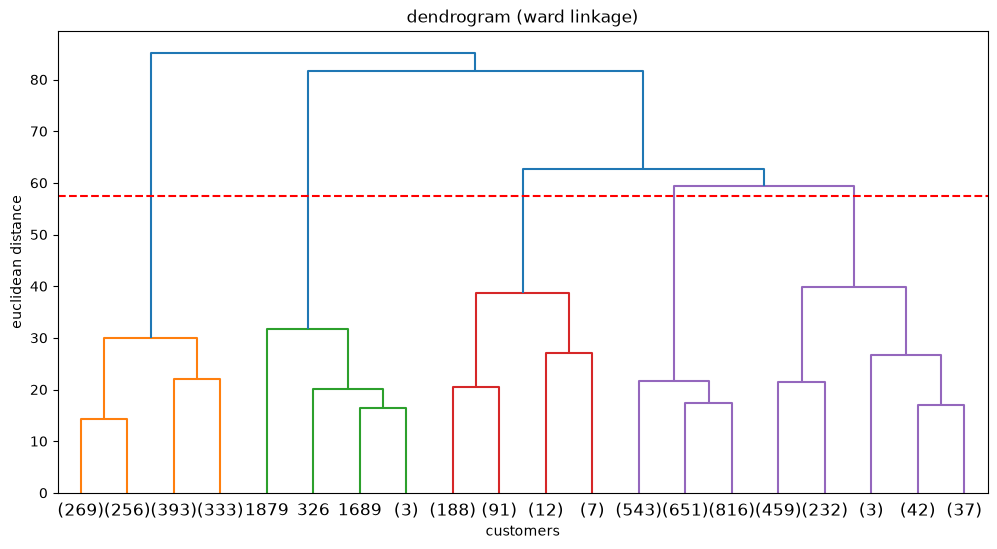

In [105]:
plt.figure(figsize=(12,6))
plt.title('dendrogram (ward linkage)')
plt.xlabel('customers')
plt.ylabel('euclidean distance')
shc.dendrogram(z, truncate_mode='lastp', p=20, show_leaf_counts=True)
plt.axhline(y=57.5, c='red', linestyle='--')
plt.show()

The optimal number of clusters will be the number of vertical lines that intersect the newly added red horizontal line. From that, the optimal k from this method is 5. However, I will cross check with the silhouette scores from the different Ks.

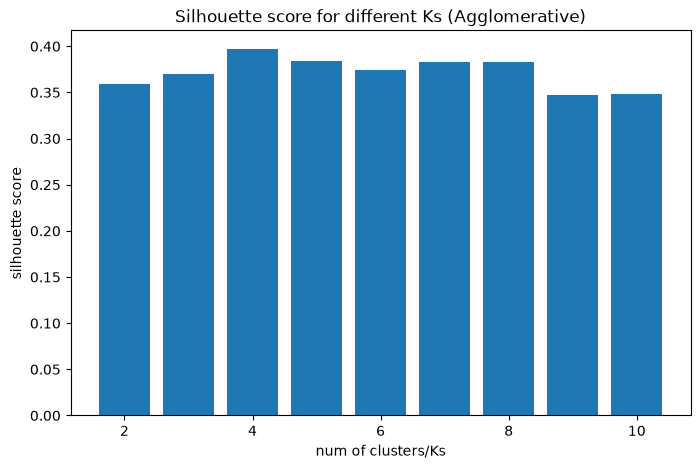

In [106]:
hier_silhouette = []  #score is only defined for k >= 2
for k in range(2,11):
    agg = AgglomerativeClustering(n_clusters=k, linkage='ward')
    labels = agg.fit_predict(rfm_s_df)
    hier_silhouette.append(silhouette_score(rfm_s_df, labels))

plt.figure(figsize=(8,5))
plt.bar(range(2,11), hier_silhouette)
plt.title('Silhouette score for different Ks (Agglomerative)')
plt.xlabel('num of clusters/Ks')
plt.ylabel('silhouette score')
plt.show()

In [107]:
for k, s in zip(range(2,11), hier_silhouette):
    print(f'k={k}: silhouette = {s:.4f}')

k=2: silhouette = 0.3587
k=3: silhouette = 0.3701
k=4: silhouette = 0.3972
k=5: silhouette = 0.3842
k=6: silhouette = 0.3738
k=7: silhouette = 0.3831
k=8: silhouette = 0.3833
k=9: silhouette = 0.3477
k=10: silhouette = 0.3484


From the silhouette score, the highest score came from k=4, but k=5 is only a little lower and I decided to use it here to keep the number of clusters consisten with the final K-Means model, so during comparison, the 2 can have equal footing in this aspect. 
#### Build the Hierarchical/Agglomerative Clustering Model

In [27]:
hier = AgglomerativeClustering(n_clusters=5, linkage='ward')
rfm['hier_cluster'] = hier.fit_predict(rfm_s_df)

print(f'Agglo cluster sizes:\n{rfm['hier_cluster'].value_counts().sort_index()}')
print(f'silhouette score (k=5): {silhouette_score(rfm_s_df, rfm['hier_cluster'])}')

Agglo cluster sizes:
hier_cluster
0     773
1     298
2       6
3    1251
4    2010
Name: count, dtype: int64
silhouette score (k=5): 0.384178967281058


### 2.4 Evaluate and Compare the Models

#### Visualise K means cluster. 
'Monetary' is transformed with log because it is skewed and it would disrupt the scatter plot. 

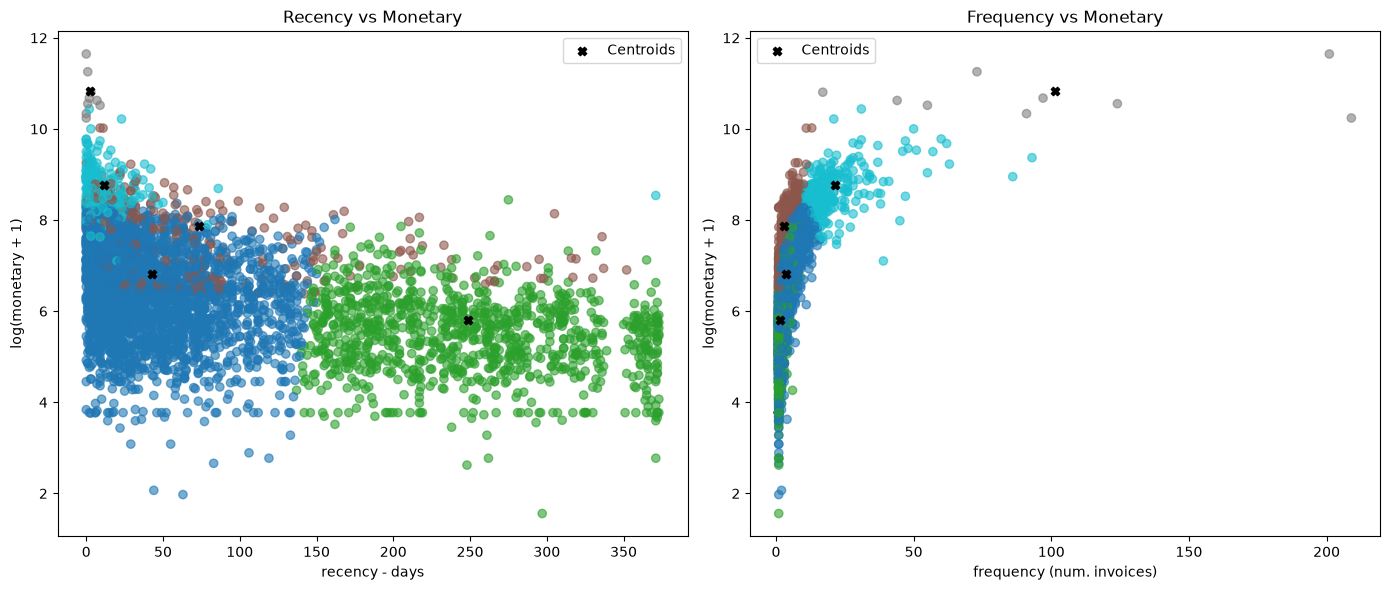

In [111]:
# inverse-transform centroids back into original (unscaled) units
og_centers = rfm_scaler.inverse_transform(km.cluster_centers_)
centers_df = pd.DataFrame(og_centers, columns=feat)  # feat=['Recency','Frequency','Monetary','AvgVal']

fig, axes = plt.subplots(1, 2, figsize=(14,6))

#use unscaled rfm to have interpretablility. when i used the scaled rfm, its hard to interpret clusters.

axes[0].scatter(rfm['Recency'], np.log1p(rfm['Monetary']), c=rfm['km_cluster'], cmap='tab10', alpha=0.6)
axes[0].scatter(centers_df['Recency'], np.log1p(centers_df['Monetary']), c='black', marker='X', label='Centroids')
axes[0].set_xlabel('recency - days')
axes[0].set_ylabel('log(monetary + 1)')
axes[0].set_title('Recency vs Monetary')
axes[0].legend()

# Frequency vs Monetary
axes[1].scatter(rfm['Frequency'], np.log1p(rfm['Monetary']), c=rfm['km_cluster'], cmap='tab10', alpha=0.6)
axes[1].scatter(centers_df['Frequency'], np.log1p(centers_df['Monetary']), c='black', marker='X', label='Centroids')
axes[1].set_xlabel('frequency (num. invoices)')
axes[1].set_ylabel('log(monetary + 1)')
axes[1].set_title('Frequency vs Monetary')
axes[1].legend()

plt.tight_layout()
plt.show()

Here, I used the scaled rfm to plot the scatter plot.

So sorry i meant to transformed instead of scaled in the video. 

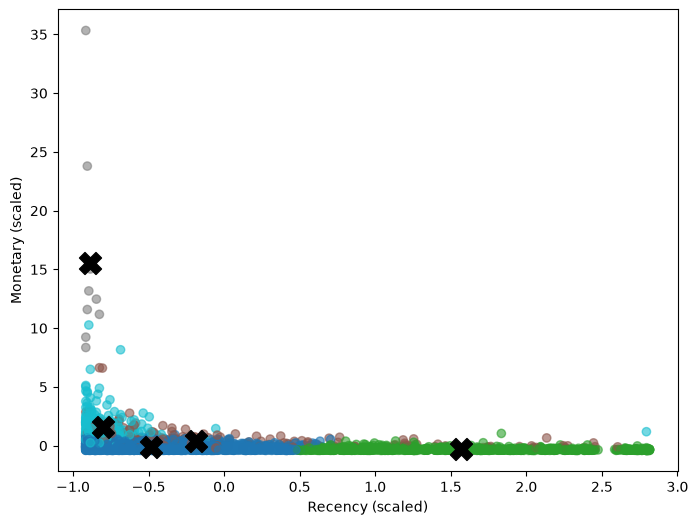

In [ ]:
plt.figure(figsize=(8,6))
plt.scatter(rfm_s_df['Recency'], rfm_s_df['Monetary'], c=rfm['km_cluster'], cmap='tab10', alpha=0.6)
plt.scatter(km.cluster_centers_[:,0], km.cluster_centers_[:,2], s=250, c='black', marker='X')  # col 0=Recency, col 2=Monetary
plt.xlabel('Recency (scaled)')
plt.ylabel('Monetary (scaled)')
plt.show()

As you can see, it is hard to form any actionable interpretability for the business, as the axis are not the actual values of the raw data points.

<hr>

##### Visualise agglomerative clustersusing the same feature pairs to create a direct comparison against k-means

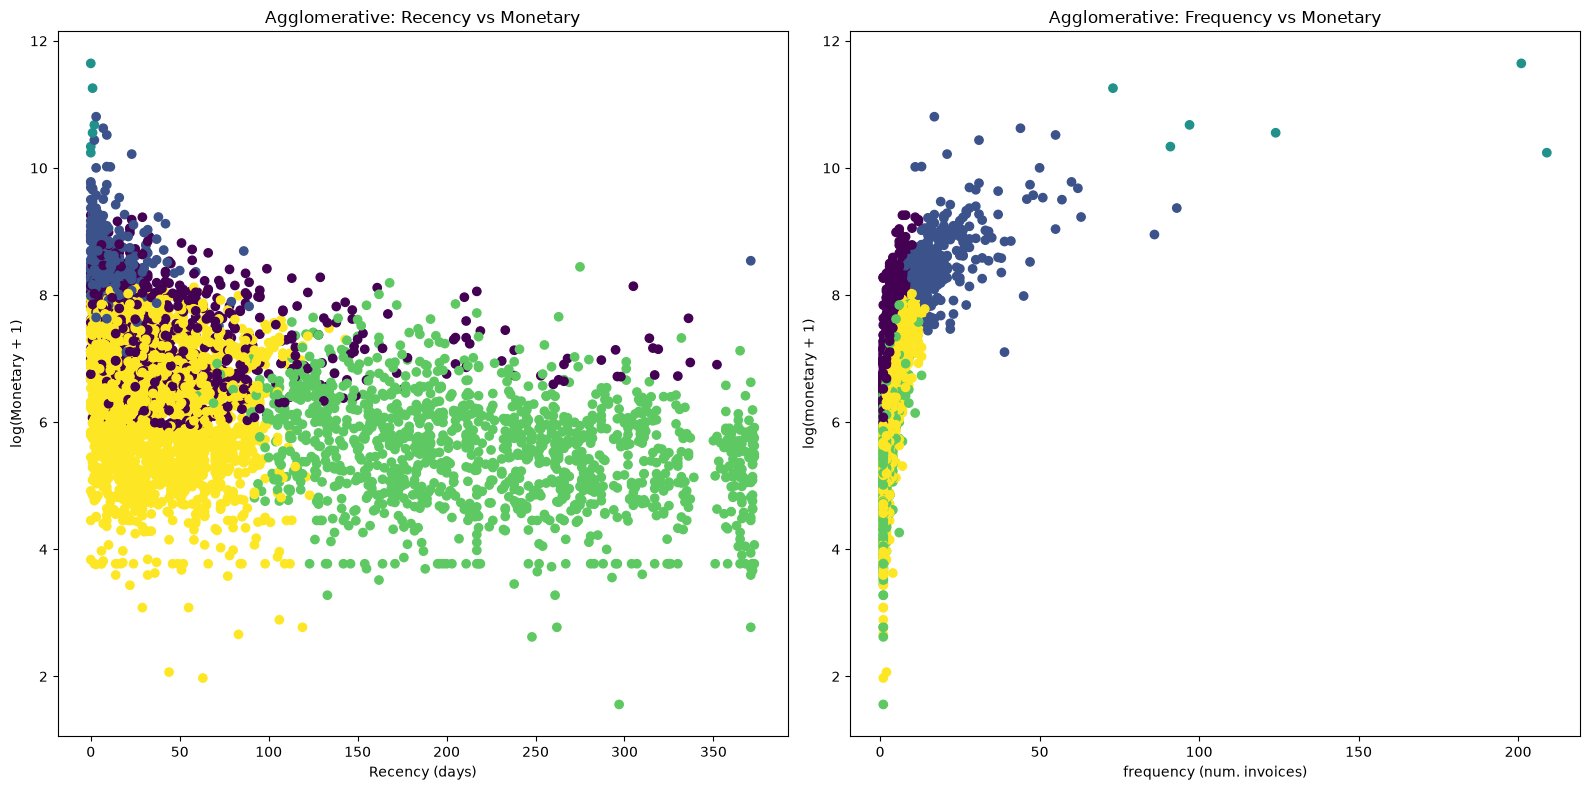

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16,8))

axes[0].scatter(rfm['Recency'], np.log1p(rfm['Monetary']), c=rfm['hier_cluster'])
axes[0].set_title('Agglomerative: Recency vs Monetary')
axes[0].set_xlabel('Recency (days)')
axes[0].set_ylabel('log(Monetary + 1)')

axes[1].scatter(rfm['Frequency'], np.log1p(rfm['Monetary']), c=rfm['hier_cluster'])
axes[1].set_title('Agglomerative: Frequency vs Monetary')
axes[1].set_xlabel('frequency (num. invoices)')
axes[1].set_ylabel('log(monetary + 1)')

plt.tight_layout()
plt.show()

<hr>

#### RFM feature distribution across the clusters for each model using boxplots.
##### K-Means Cluster

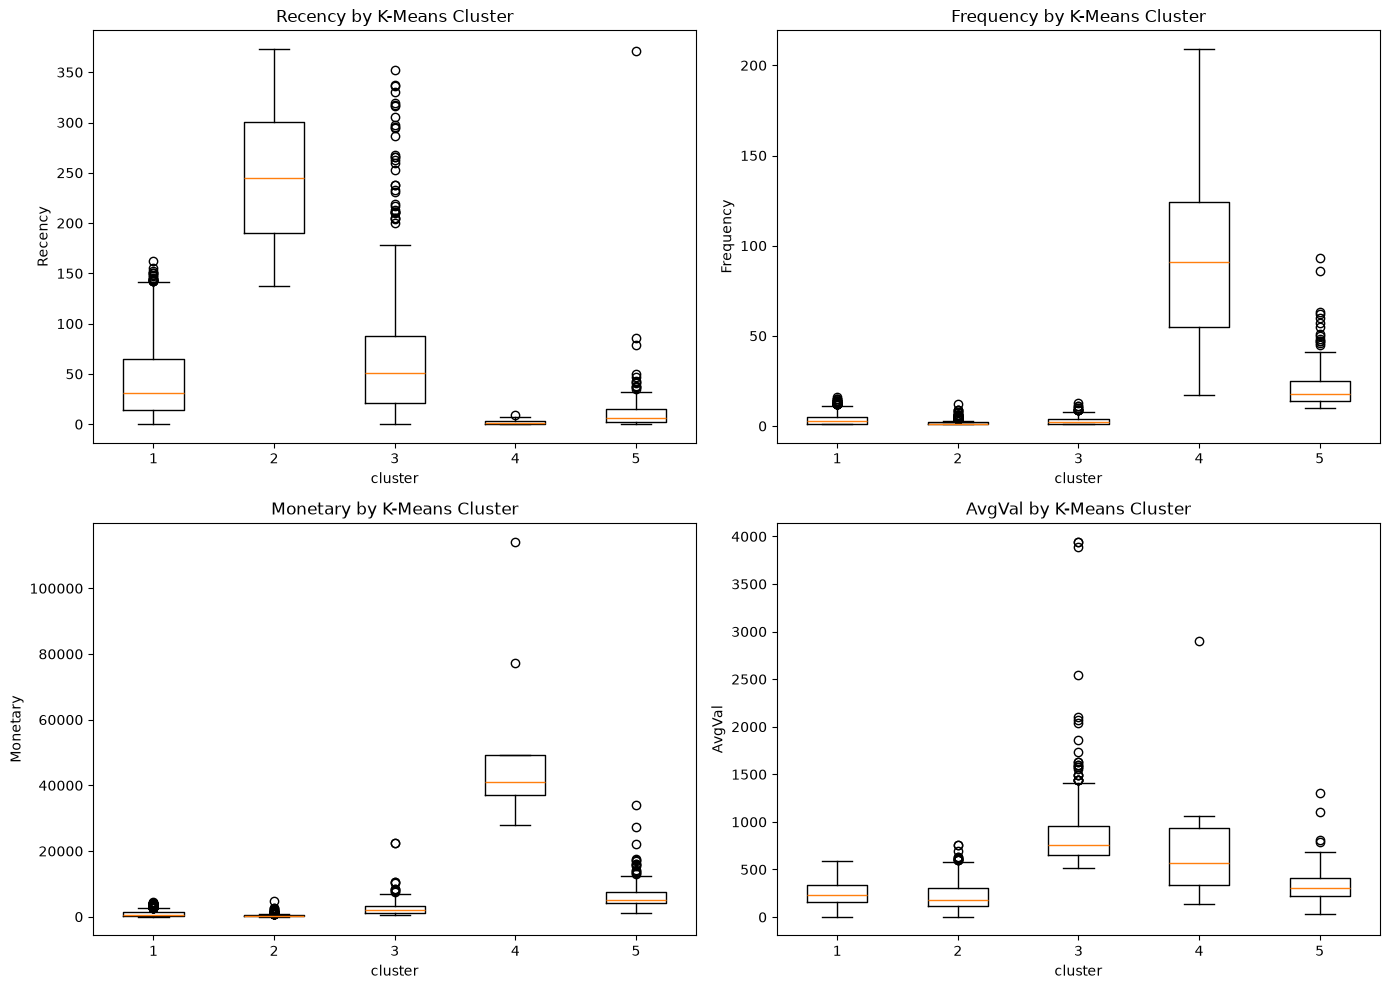

In [ ]:
features = ['Recency', 'Frequency', 'Monetary', 'AvgVal']

fig, axes = plt.subplots(2, 2, figsize=(14,10))
axes = axes.ravel()

for i, feat in enumerate(features):
    data_by_cluster = [rfm[rfm['km_cluster'] == c][feat] for c in sorted(rfm['km_cluster'].unique())]
    axes[i].boxplot(data_by_cluster, label=sorted(rfm['km_cluster'].unique()))
    axes[i].set_title(f'{feat} by K-Means Cluster')
    axes[i].set_xlabel('cluster')
    axes[i].set_ylabel(feat)

plt.tight_layout()
plt.show()

##### Agglomerative Cluster

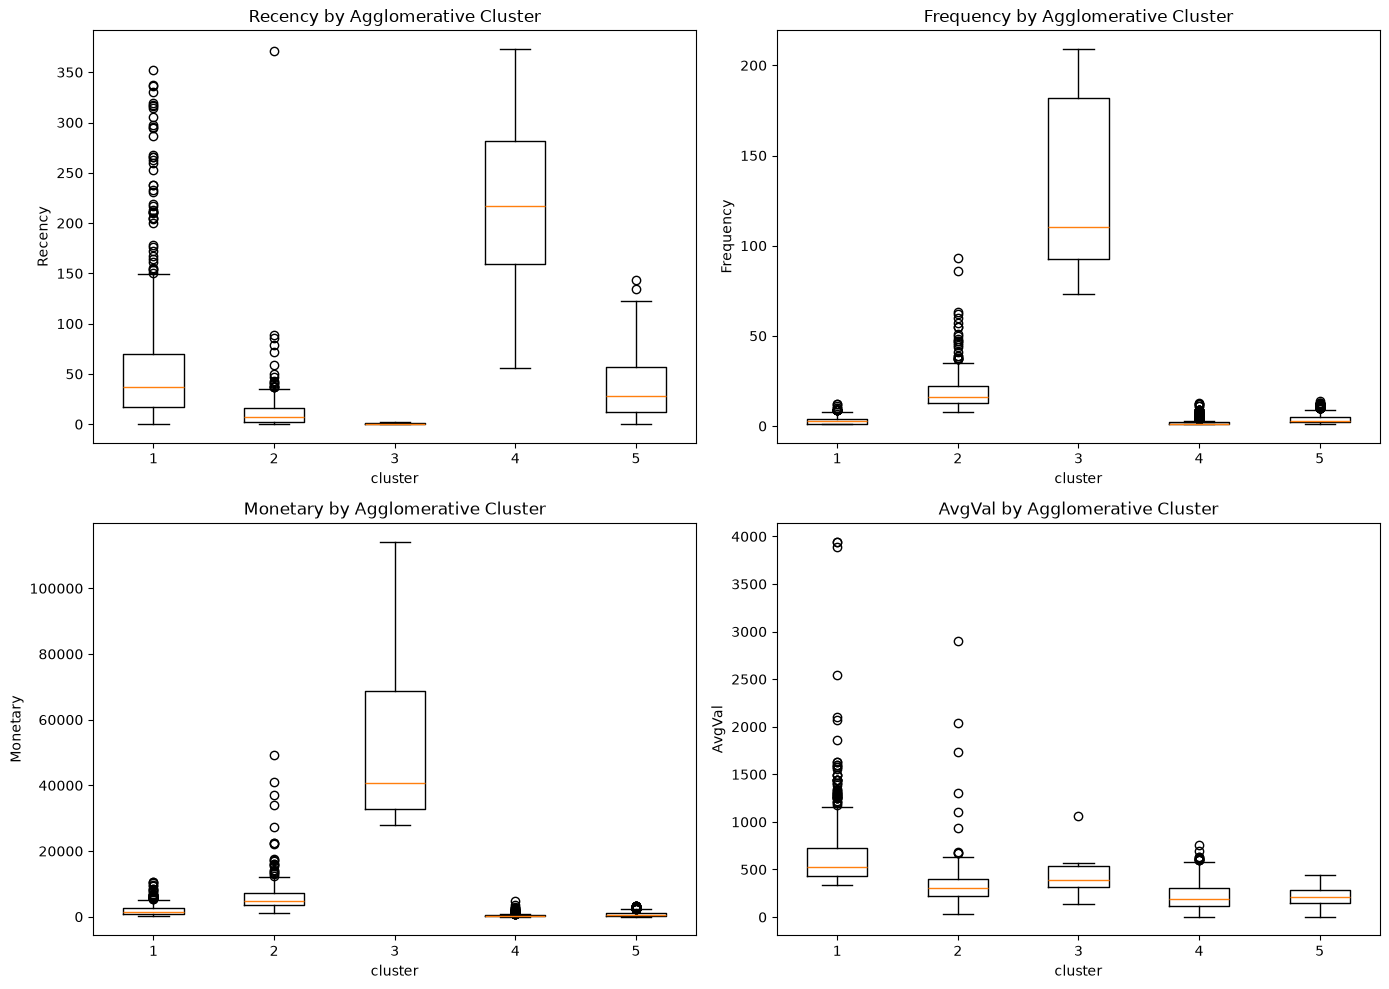

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14,10))
axes = axes.ravel()

for i, feat in enumerate(features):
    data_by_cluster = [rfm[rfm['hier_cluster'] == c][feat] for c in sorted(rfm['hier_cluster'].unique())]
    axes[i].boxplot(data_by_cluster, label=sorted(rfm['hier_cluster'].unique()))
    axes[i].set_title(f'{feat} by Agglomerative Cluster')
    axes[i].set_xlabel('cluster')
    axes[i].set_ylabel(feat)

plt.tight_layout()
plt.show()

<hr>

### Compare silhouette scores of both models at k=5.

In [113]:
compare = pd.DataFrame({'Model': ['K-Means', 'Agglomerative'],
                        'k': [5, 5],
                        'silhouette score':[silhouette_score(rfm_s_df, rfm['km_cluster']),
                                            silhouette_score(rfm_s_df, rfm['hier_cluster'])]})
compare

,Model,k,silhouette score
0,K-Means,5,0.477269
1,Agglomerative,5,0.384179


The K-Means model has the higher silhouette score, indicating that its clusters are more compact and better separated compared to the agglomerative model. **K-Means will therefore be chosen as the preferred model** for further exploration and segment interpretation. <hr>

### Assign behaviour to segments

Get the mean for RFM to better understand customer behaviour per segment. 

In [ ]:
cluster_mean = rfm.groupby('km_cluster')[features].agg(['mean', 'count'])
cluster_mean

Recency         Frequency            Monetary        \
                  mean count        mean count          mean count   
km_cluster                                                           
0            42.870296  2737    3.599196  2737    917.368631  2737   
1           248.488189  1016    1.557087  1016    329.774094  1016   
2            73.143284   335    3.089552   335   2599.037734   335   
3             2.555556     9  101.222222     9  51079.802222     9   
4            11.448133   241   21.381743   241   6418.961120   241   

                AvgVal        
                  mean count  
km_cluster                    
0           253.809620  2737  
1           216.786542  1016  
2           882.646047   335  
3           818.872465     9  
4           327.114837   241

***Refresher*** <br>
Recency: days since the customer's last purchase (mean=248 = the average last purchase made was 248 days ago) - <b>bigger = worse</b><br>
Frequency: how many orders the same customer placed - **bigger = better**<br>
Monetary: how much money a customer spent in total, across all their orders - **bigger = better**

To allow for easier interpretability, assign non-technical names to the segmenets based on their segment.

In [ ]:
names = {
    0: 'active reoccurring customers',
    1: 'at-risk-of-losing customers',
    2: 'occasional high spenders',
    3: 'top-tier highest spenders',
    4: 'recent high spending customers'
}

rfm['Segments'] = rfm['km_cluster'].map(names)
rfm[['CustomerID', 'Recency', 'Frequency', 'Monetary', 'AvgVal', 'Segments']].head()

,CustomerID,Recency,Frequency,Monetary,AvgVal,Segments
0,12346.0,325,1,42.48,42.480000,at-risk-of-losing customers
1,12347.0,1,7,3769.34,538.477143,active reoccurring customers
2,12348.0,74,4,1111.40,277.850000,active reoccurring customers
3,12349.0,18,1,1442.71,1442.710000,occasional high spenders
4,12350.0,309,1,334.40,334.400000,at-risk-of-losing customers


<hr>

## 2.5 Summarize and Interpret

In [ ]:
summary_table = rfm.groupby('Segments')[['Recency','Frequency','Monetary','AvgVal']].mean().round(1)
summary_table['num custs'] = rfm['Segments'].value_counts()
summary_table = summary_table.sort_values('Monetary', ascending=False)
summary_table

,Recency,Frequency,Monetary,AvgVal,num custs
Segments,,,,,
top-tier highest spenders,2.6,101.2,51079.8,818.9,9
recent high spending customers,11.4,21.4,6419.0,327.1,241
occasional high spenders,73.1,3.1,2599.0,882.6,335
active reoccurring customers,42.9,3.6,917.4,253.8,2737
at-risk-of-losing customers,248.5,1.6,329.8,216.8,1016


K-Means (k=5) was preferred over Agglomerative Clustering on silhouette score (0.477 vs 0.384), and its 5 clusters mapped cleanly into interpretable segments. 

<hr>

**Segment interpretation and their corresponding business actions that can be taken**
| | Recency | Frequency | Monetary |
| --- | --- | --- | --- |
| top-tier highest spenders | very low | very high | very high |
| recent high spending customers | low | high | high |
| occasional high spenders | moderate | low-moderate | high |
| active reoccurring customers | low | moderate | moderate |
| at-risk-of-losing customers | very high | low | low |


**top-tier highest spenders**: Since they are a small group, it is best to retain them at all cost. This can be done with dedicated personal account management, exclusive offers/discounts, and maybe even early access to new products.<br>
**recent high spending customers**: The company can slowly nurture this group with loyalty rewards and try to upsell offers to push them towards the top-tier highest spenders segment. This segment has strongest potential top-tier highest spenders customers. <br>
**occasional high spenders**: This group can be targeted with occasional reminder to shop, since they spend quite a bit every visit, but do not visit often.<br>
**active reoccurring customers**: The largest group and the middle ground. The organization can strive to maintain frequent engagement with promotions with this particular group. They can also cross-sell to increase this group's basket size. <br>
**at-risk-of-losing customers**: The organization can send win-back campaign to these customers' emails and discounts before they completely lose engagement. This is a low cost recommendation too as it can be automated. 

In summary, K-Means was the better clustering model for customer segmentation. This was concluded from the visual separation of the clusters and its silhouette score. The online retailer should consider taking action for these groups increaase its profit long-term. 